# Earnings Disclosure Spillovers and Peer-Return Prediction

Do corporate-disclosure features improve forecasts of a semiconductor peer's five-session return relative to SPY?

This notebook reruns the original study, then a revision with corrected text inputs and model selection. Both use the same historical sample. The tables compare forecast error, interval quality, and results across companies and years.

Run `uv sync --locked --extra research --extra test` from the repository root, then select the installed environment as this notebook's Python kernel. Saved outputs are readable without running anything. After installation, all cells run offline. Derived files go to `out/relay-notebook/` and `out/earnings-notebook-analysis/`; the included inputs and original results remain unchanged.

The replay begins from frozen numerical inputs. It does not re-download prices, re-extract SEC disclosures, or verify the original source archives.

In [1]:
from datetime import date
from pathlib import Path
import math

import pandas as pd
from IPython.display import Image, display
import relay
from relay.reproduce import reproduce
from relay.research import analyze
from relay.figures import plot_diagnostics

repo_root = Path(relay.__file__).resolve().parents[1]
assert (repo_root / "pyproject.toml").is_file(), "Use an editable install of the earnings-study checkout."
output = repo_root / "out" / "relay-notebook"
analysis_output = repo_root / "out" / "earnings-notebook-analysis"
print("Using the editable checkout; derived outputs stay separate from the included references.")

Using the editable checkout; derived outputs stay separate from the included references.


## 1. Original reference: methods and replay

The cohort contains AMD, NVDA, INTC, QCOM, TXN and MU. Every other company in the cohort is treated as a peer; these links are study assumptions, not verified supplier relationships.

The target is the peer's adjusted open-to-close return over five holding sessions minus SPY's return over the same sessions. Features are observed at the first session's close strictly after the later of the SEC filing date and known acceptance timestamp's New York date. Entry is the next session's adjusted open. This is a delayed filing-based window, not the original earnings-release instant or a beta-neutral return.

Four fixed models use identical observations: zero excess return, ridge regression with price controls, added source-price/network features, and added disclosure-language features. Quarterly folds use earlier data for fitting and a separate calibration period. Labels crossing a boundary are purged; feature normalization is fitted on training data only.

The nominal 80% intervals are empirical quantiles of calibration residuals. They are not finite-sample conformal intervals and have no coverage guarantee under market shifts. The replay below verifies its fixture and compares rebuilt metrics with the saved reference.

In [2]:
report = reproduce(output=output)

assert report["status"] == "verified", report["status"]
verification = report["verification"]
max_error = float(verification["max_metric_error"])
tolerance = float(verification["tolerance"])
assert math.isfinite(max_error) and math.isfinite(tolerance)
assert 0 <= max_error <= tolerance

metrics = pd.DataFrame(report["metrics"]).set_index("model_id", verify_integrity=True)
expected_models = {"zero_excess", "price_only", "network", "event_conditioned"}
assert set(metrics.index) == expected_models
assert report["sample"]["predicted_rows"] == 1050
assert metrics["n"].eq(1050).all()

print(f"Status: {report['status']}")
print(f"Scope: {report['scope']}")
print(f"Largest metric difference: {max_error:.3g}; tolerance: {tolerance:.3g}")
pd.Series(report["sample"], name="Rows").to_frame()


Status: verified
Scope: model_stage_replay
Largest metric difference: 0; tolerance: 1e-10


/var/folders/7m/h1nq0h550zz0syygmyfq4xh40000gn/T/ipykernel_78997/74180602.py:10: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  metrics = pd.DataFrame(report["metrics"]).set_index("model_id", verify_integrity=True)


,Rows
input_rows,1205
valid_rows,1205
predicted_rows,1050


## Check chronological separation

A fitting label must finish strictly before the calibration period starts. A calibration label must finish strictly before the test quarter starts. These are stronger checks than ordering feature dates alone. Early quarters without enough prior fitting and calibration data are skipped.


In [3]:
evaluated = [fold for fold in report["folds"] if fold["status"] == "evaluated"]
assert len(evaluated) == 35
assert metrics["fold_count"].eq(len(evaluated)).all()
assert sum(fold["test"]["n_rows"] for fold in evaluated) == 1050

for fold in evaluated:
    fit_exit = date.fromisoformat(fold["fit"]["latest_exit"])
    calibration_start = date.fromisoformat(fold["calibration_start"])
    calibration_exit = date.fromisoformat(fold["calibration"]["latest_exit"])
    test_start = date.fromisoformat(fold["fold_start"])
    assert fit_exit < calibration_start, f"Fit/calibration overlap in {fold['fold_id']}"
    assert calibration_exit < test_start, f"Calibration/test overlap in {fold['fold_id']}"

fold_table = pd.DataFrame([
    {
        "Quarter": fold["fold_id"],
        "Fit latest exit": fold["fit"]["latest_exit"],
        "Calibration starts": fold["calibration_start"],
        "Calibration latest exit": fold["calibration"]["latest_exit"],
        "Test starts": fold["fold_start"],
        "Test rows": fold["test"]["n_rows"],
    }
    for fold in evaluated
])
print(f"Checked both timing boundaries in {len(evaluated)} evaluated folds.")
fold_table


Checked both timing boundaries in 35 evaluated folds.


,Quarter,Fit latest exit,Calibration starts,Calibration latest exit,Test starts,Test rows
0,2018Q2,2017-12-28,2018-01-24,2018-03-07,2018-04-01,30
1,2018Q3,2018-02-16,2018-02-28,2018-06-28,2018-07-01,35
2,2018Q4,2018-05-04,2018-05-11,2018-09-28,2018-10-01,30
3,2019Q1,2018-06-28,2018-07-26,2018-12-27,2019-01-01,35
4,2019Q2,2018-09-28,2018-10-26,2019-03-28,2019-04-01,30
5,2019Q3,2018-12-27,2019-01-24,2019-05-24,2019-07-01,30
6,2019Q4,2019-02-07,2019-02-15,2019-08-23,2019-10-01,30
7,2020Q1,2019-05-01,2019-05-02,2019-12-27,2020-01-01,30
8,2020Q2,2019-07-03,2019-07-26,2020-02-24,2020-04-01,30
9,2020Q3,2019-10-04,2019-10-23,2020-06-01,2020-07-01,30


## Compare forecast error and coverage

MAE and RMSE are in percentage points of five-session SPY-relative return; lower is better. Coverage is the fraction of realized returns inside each model's nominal 80% interval.


In [4]:
metric_table = pd.DataFrame({
    "Model": metrics["name"],
    "Forecasts": metrics["n"].astype(int),
    "MAE (pp)": (100 * metrics["mae"]).round(2),
    "RMSE (pp)": (100 * metrics["rmse"]).round(2),
    "80% interval coverage (%)": (100 * metrics["interval_coverage"]).round(1),
}).reset_index(drop=True)
metric_table


,Model,Forecasts,MAE (pp),RMSE (pp),80% interval coverage (%)
0,Zero excess return,1050,3.81,5.37,74.9
1,Price controls,1050,3.90,5.49,74.2
2,Network spillover,1050,3.95,5.56,73.9
3,Event-conditioned spillover,1050,4.19,5.88,75.1


In [5]:
event = metrics.loc["event_conditioned"]
for baseline_id in ("zero_excess", "price_only", "network"):
    baseline = metrics.loc[baseline_id]
    difference = 100 * (event["mae"] - baseline["mae"])
    direction = "higher" if difference > 0 else "lower" if difference < 0 else "equal"
    print(f"Event-conditioned MAE versus {baseline['name']}: {abs(difference):.2f} pp {direction}.")

if event["mae"] > metrics.loc["price_only", "mae"]:
    print("Adding the source-price and disclosure-language features did not improve MAE over price controls in this saved sample.")

below_target = metrics.loc[metrics["interval_coverage"] < 0.8, "name"].tolist()
print(f"Models below nominal 80% coverage: {', '.join(below_target) or 'none'}.")
print("Matching the reference establishes model-stage reproducibility, not a trading edge.")


Event-conditioned MAE versus Zero excess return: 0.38 pp higher.
Event-conditioned MAE versus Price controls: 0.29 pp higher.
Event-conditioned MAE versus Network spillover: 0.24 pp higher.
Adding the source-price and disclosure-language features did not improve MAE over price controls in this saved sample.
Models below nominal 80% coverage: Zero excess return, Price controls, Network spillover, Event-conditioned spillover.
Matching the reference establishes model-stage reproducibility, not a trading edge.


## 2. Corrected study: feature contributions and uncertainty

The second fixture records the corrected numerical inputs and exact study configuration. The four fixed models stay in the comparison. A fifth model selects among nine prespecified candidates using a purged earlier/later split inside the fitting sample, before calibration and quarterly testing.

The corrected fixture is independently hashed. Model-stage results are checked against its saved metrics; this validates replay, not the decision to make changes after seeing historical outcomes. The original reference above is preserved.

In [6]:
corrected = analyze(output=analysis_output)
current_metrics = pd.DataFrame(corrected["metrics"]).set_index("model_id", verify_integrity=True)
assert set(current_metrics.index) == expected_models | {"adaptive"}
assert current_metrics["n_predictions"].eq(corrected["fixture"]["predictions"]).all()
assert current_metrics["n_predictions"].eq(metrics["n"].iloc[0]).all()

comparison = pd.DataFrame({
    "Original MAE (pp)": 100 * metrics["mae"],
    "Corrected MAE (pp)": 100 * current_metrics["mae"],
    "Corrected RMSE (pp)": 100 * current_metrics["rmse"],
})
comparison.index = [current_metrics.loc[model, "name"] for model in comparison.index]
comparison.index.name = "Model"
print("Lower error is better. A blank original value means that model was not in the original reference.")
comparison.round(3)

Lower error is better. A blank original value means that model was not in the original reference.


/var/folders/7m/h1nq0h550zz0syygmyfq4xh40000gn/T/ipykernel_78997/929198524.py:2: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  current_metrics = pd.DataFrame(corrected["metrics"]).set_index("model_id", verify_integrity=True)


,Original MAE (pp),Corrected MAE (pp),Corrected RMSE (pp)
Model,,,
Training-selected model,NaN,3.844,5.407
Event-conditioned spillover,4.188,3.963,5.569
Network spillover,3.951,3.951,5.561
Price controls,3.903,3.903,5.492
Zero excess return,3.810,3.810,5.374


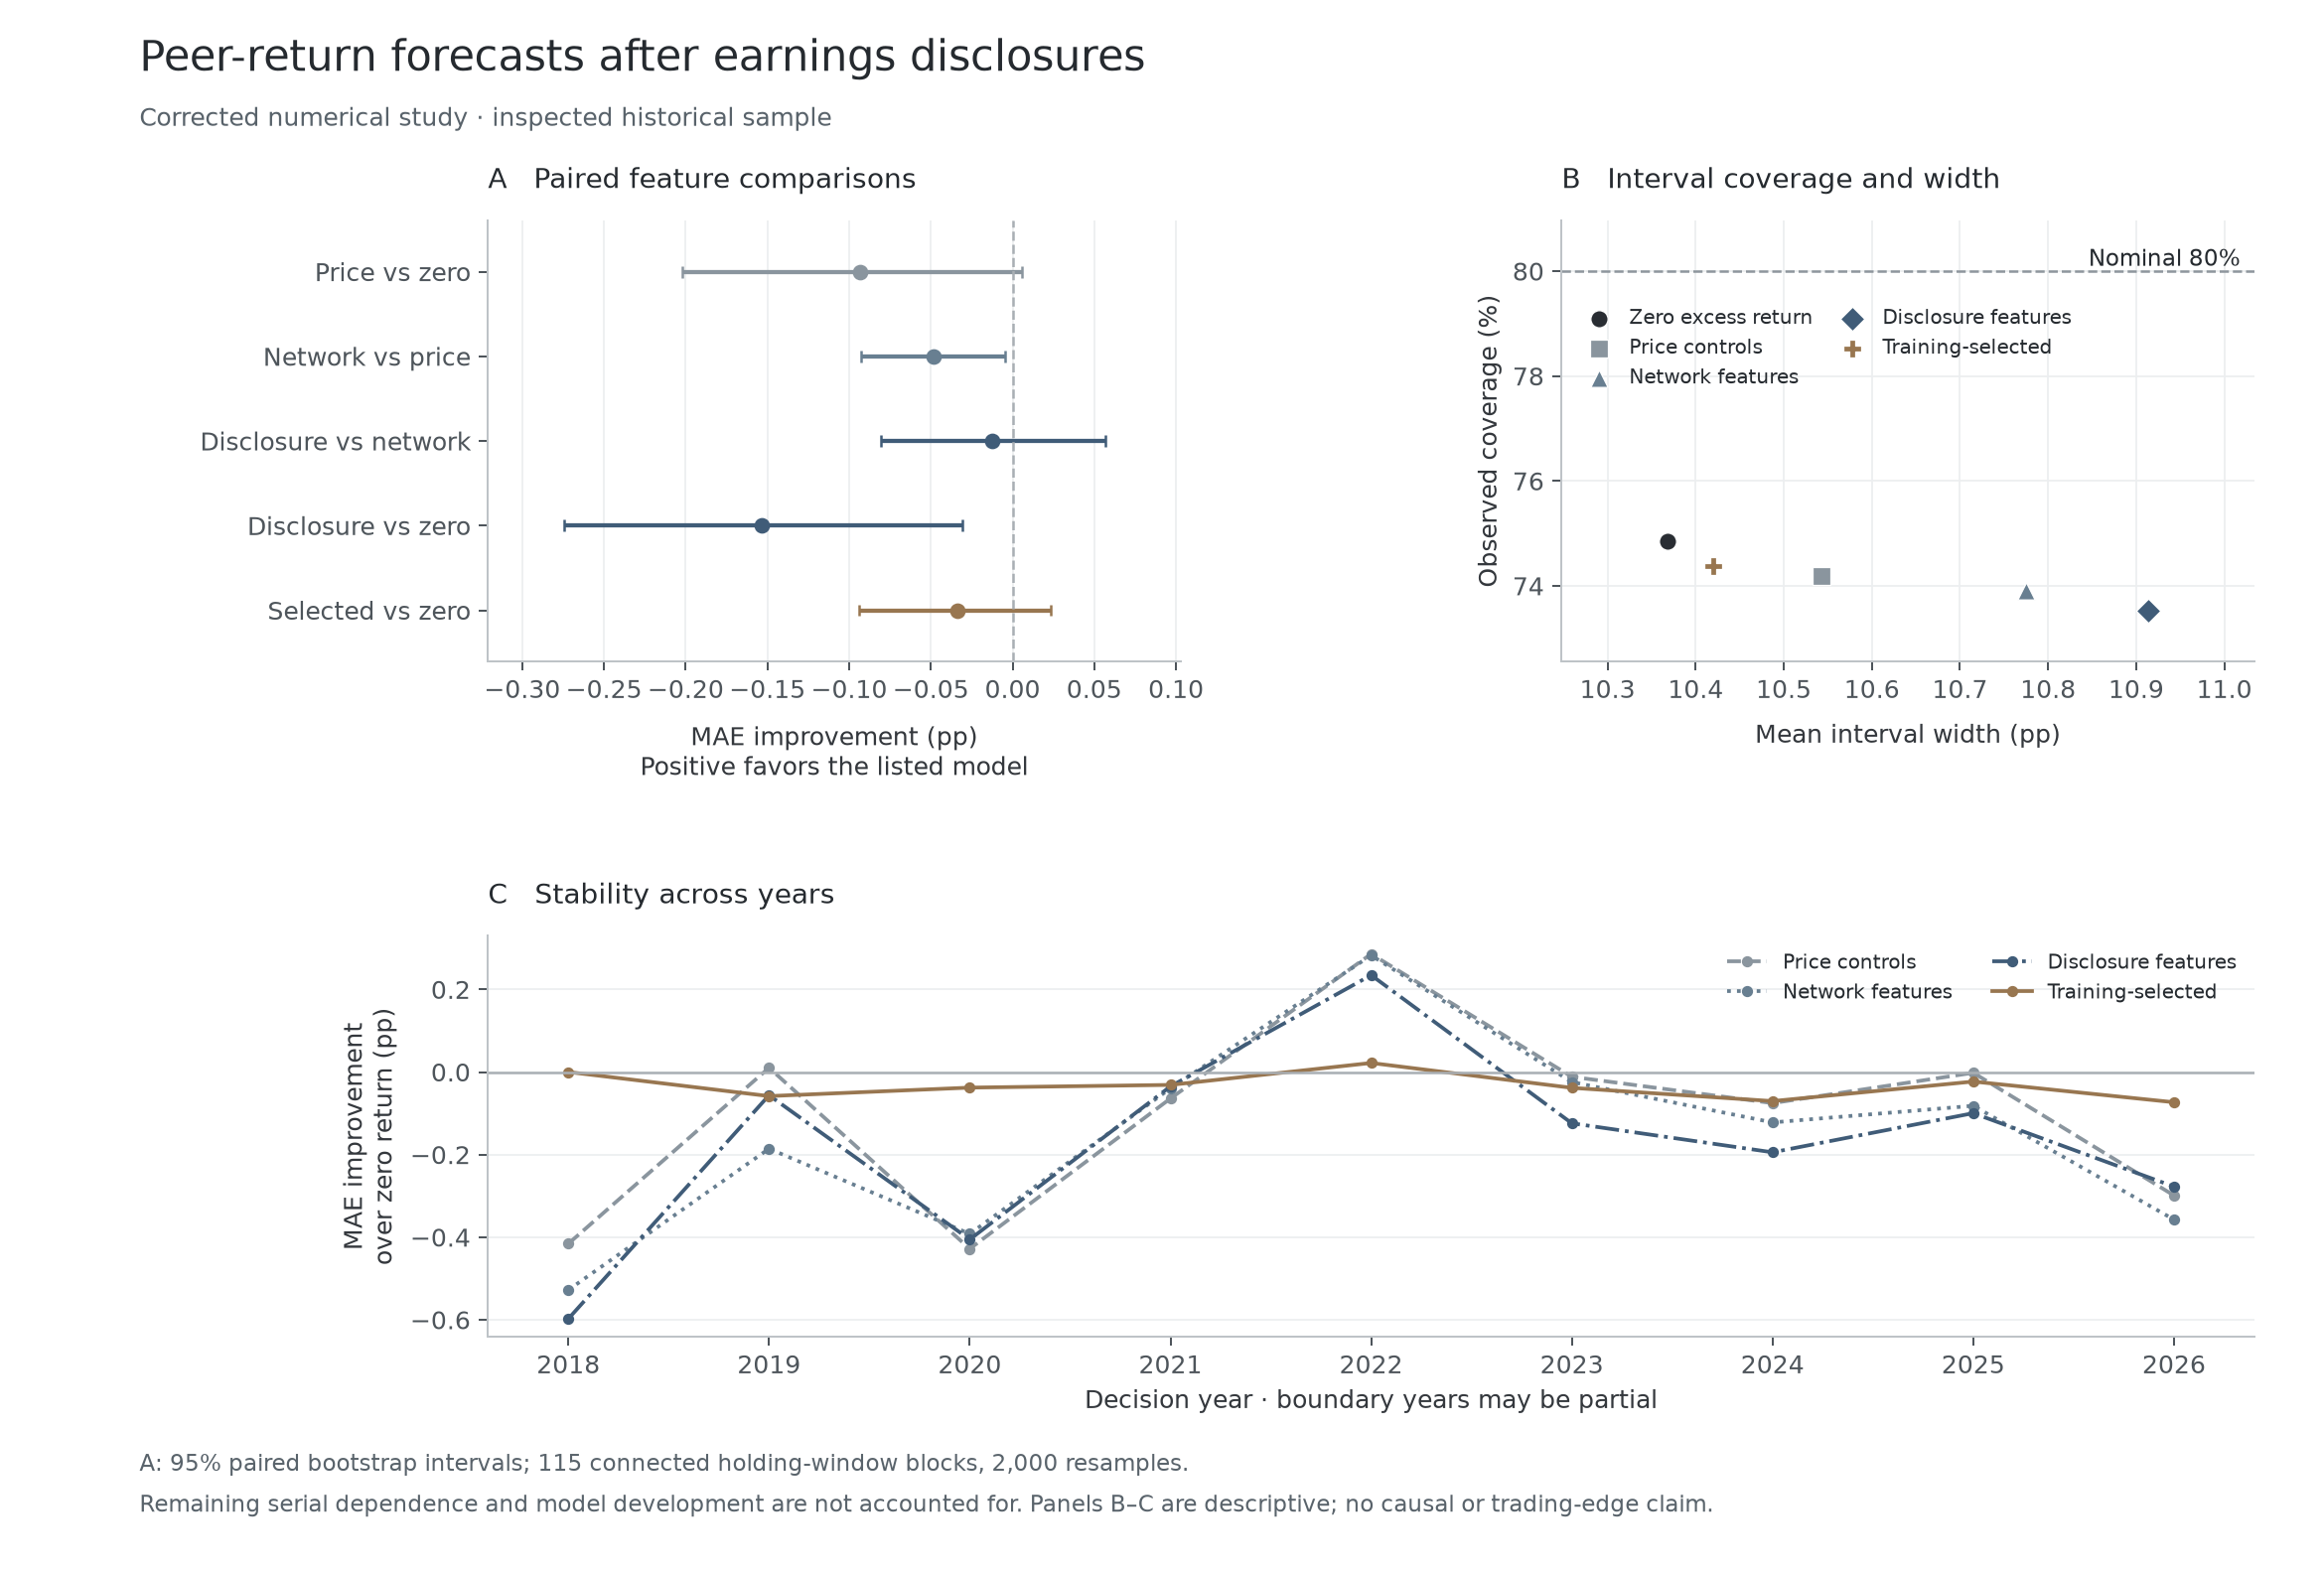

In [7]:
plot_diagnostics(corrected, analysis_output)
display(Image(filename=str(analysis_output / "diagnostics.png"), width=1100))

### Paired feature comparisons

Each difference uses forecasts for exactly the same event–peer outcomes. Positive improvement means lower MAE for the listed model. The disclosure-versus-network comparison measures what the text features add. The selected-versus-zero comparison tests model selection against the simplest baseline.

Uncertainty resamples connected blocks of overlapping holding windows, keeping all peers and all models in a block together. This also groups transitively overlapping windows. The 95% percentile intervals use 2,000 resamples and a fixed seed. Remaining dependence between blocks, multiple comparisons, and development on already-inspected outcomes are not corrected. These are exploratory intervals, not confirmatory significance tests.

In [8]:
ablations = pd.DataFrame(corrected["ablations"])
paired_table = pd.DataFrame({
    "Model": ablations["model_id"].map(current_metrics["name"]),
    "Baseline": ablations["baseline_model_id"].map(current_metrics["name"]),
    "MAE improvement (pp)": 100 * ablations["mae_improvement"],
    "95% lower (pp)": 100 * ablations["ci_lower"],
    "95% upper (pp)": 100 * ablations["ci_upper"],
    "Blocks": ablations["n_clusters"],
})
paired_table.round(3)

,Model,Baseline,MAE improvement (pp),95% lower (pp),95% upper (pp),Blocks
0,Price controls,Zero excess return,-0.093,-0.202,0.006,115
1,Network spillover,Price controls,-0.048,-0.093,-0.004,115
2,Event-conditioned spillover,Network spillover,-0.012,-0.080,0.057,115
3,Event-conditioned spillover,Zero excess return,-0.153,-0.275,-0.031,115
4,Training-selected model,Zero excess return,-0.034,-0.094,0.023,115


### Coverage, sharpness, and interval score

Coverage alone can be raised by making intervals wider. The mean interval width measures that cost. The interval score jointly penalizes width and missed outcomes:

$$S_{\alpha}(l,u;y)=(u-l)+\frac{2}{\alpha}(l-y)\mathbf{1}(y<l)+\frac{2}{\alpha}(y-u)\mathbf{1}(y>u),\qquad \alpha=0.2.$$

Lower interval score is better. Width and score below are expressed in percentage points. Brier error evaluates the probability of a strictly positive excess return; lower is better. The score follows [Gneiting and Raftery (2007), section 6.2](https://doi.org/10.1198/016214506000001437).

In [9]:
interval_table = pd.DataFrame({
    "Model": current_metrics["name"],
    "Coverage (%)": 100 * current_metrics["interval_coverage"],
    "Mean width (pp)": 100 * current_metrics["mean_interval_width"],
    "Interval score (pp)": 100 * current_metrics["interval_score"],
    "Brier error": current_metrics["brier"],
}).reset_index(drop=True)
print("Nominal coverage: 80%. The point forecast and the probability forecast are separate outputs.")
interval_table.round(3)

Nominal coverage: 80%. The point forecast and the probability forecast are separate outputs.


,Model,Coverage (%),Mean width (pp),Interval score (pp),Brier error
0,Zero excess return,74.857,10.368,19.810,0.257
1,Price controls,74.190,10.543,20.667,0.265
2,Network spillover,73.905,10.775,21.034,0.269
3,Event-conditioned spillover,73.524,10.914,21.231,0.270
4,Training-selected model,74.381,10.420,20.128,0.260


### Stability across years and companies

Every observed year, source company, and target company appears below. These are descriptive slices of the same fitted forecasts, not leave-one-company-out retraining or new holdouts. Differences are zero-baseline MAE minus model MAE, so positive values favor the model. Counts show the size of each slice.

In [10]:
slice_rows = pd.DataFrame([
    {"Dimension": group["dimension"], "Group": group["value"],
     "Model": row["model_id"], "Forecasts": row["n_predictions"],
     "Events": row["n_events"], "MAE": row["mae"]}
    for group in corrected["slices"] for row in group["metrics"]
])
for dimension, label in (("year", "Decision year"), ("source_ticker", "Source company"), ("target_ticker", "Target company")):
    rows = slice_rows.loc[slice_rows["Dimension"].eq(dimension)]
    table = rows.pivot(index="Group", columns="Model", values="MAE")
    improvement = table.sub(table["zero_excess"], axis=0).mul(-100).drop(columns="zero_excess")
    improvement = improvement.rename(columns=current_metrics["name"].to_dict()).round(3)
    counts = rows.loc[rows["Model"].eq("zero_excess")].set_index("Group")
    improvement.insert(0, "Forecasts", counts["Forecasts"])
    improvement.insert(1, "Events", counts["Events"])
    improvement.index.name = label
    print(f"{label}: MAE improvement over zero excess return (pp)")
    display(improvement)

Decision year: MAE improvement over zero excess return (pp)


Model,Forecasts,Events,Training-selected model,Event-conditioned spillover,Network spillover,Price controls
Decision year,,,,,,
2018,95,19,-0.000,-0.598,-0.528,-0.416
2019,125,25,-0.058,-0.056,-0.186,0.010
2020,115,23,-0.038,-0.406,-0.392,-0.428
2021,130,26,-0.031,-0.035,-0.040,-0.064
2022,130,26,0.022,0.235,0.282,0.286
2023,120,24,-0.038,-0.124,-0.024,-0.012
2024,120,24,-0.070,-0.194,-0.122,-0.075
2025,120,24,-0.023,-0.100,-0.082,-0.002
2026,95,19,-0.073,-0.277,-0.357,-0.299


Source company: MAE improvement over zero excess return (pp)


Model,Forecasts,Events,Training-selected model,Event-conditioned spillover,Network spillover,Price controls
Source company,,,,,,
AMD,175,35,-0.061,-0.194,-0.066,0.002
INTC,175,35,-0.073,-0.371,-0.175,-0.097
MU,170,34,-0.014,-0.124,-0.143,-0.159
NVDA,180,36,-0.133,-0.195,-0.163,-0.163
QCOM,170,34,0.143,-0.098,-0.129,-0.098
TXN,180,36,-0.057,0.060,-0.169,-0.045


Target company: MAE improvement over zero excess return (pp)


Model,Forecasts,Events,Training-selected model,Event-conditioned spillover,Network spillover,Price controls
Target company,,,,,,
AMD,175,175,0.029,-0.255,-0.264,-0.180
INTC,175,175,-0.137,-0.280,-0.307,-0.236
MU,176,176,-0.042,-0.098,-0.154,-0.111
NVDA,174,174,0.107,0.065,0.101,0.136
QCOM,176,176,-0.057,-0.014,0.041,0.014
TXN,174,174,-0.102,-0.339,-0.265,-0.181


### Concurrent peer disclosures

A peer may release its own disclosure during the source event's holding window. The table separates flagged and unflagged outcomes using the included observation audit. It does not refit models or establish that the unflagged sample is causally clean. The flag covers disclosures found in the collected event ledger, not every possible source of news.

In [11]:
confounds = pd.DataFrame(corrected["confounds"])
confound_table = pd.DataFrame({
    "Overlap group": confounds["value"],
    "Model": confounds["model_id"].map(current_metrics["name"]),
    "Forecasts": confounds["n_predictions"],
    "Events": confounds["n_events"],
    "MAE (pp)": 100 * confounds["mae"],
    "Coverage (%)": 100 * confounds["interval_coverage"],
})
confound_table.round(3)

,Overlap group,Model,Forecasts,Events,MAE (pp),Coverage (%)
0,no_overlap,Zero excess return,858,210,3.413,79.371
1,no_overlap,Price controls,858,210,3.496,78.788
2,no_overlap,Network spillover,858,210,3.532,78.788
3,no_overlap,Event-conditioned spillover,858,210,3.554,78.205
4,no_overlap,Training-selected model,858,210,3.436,78.904
5,overlap,Zero excess return,192,109,5.583,54.688
6,overlap,Price controls,192,109,5.721,53.646
7,overlap,Network spillover,192,109,5.826,52.083
8,overlap,Event-conditioned spillover,192,109,5.795,52.604
9,overlap,Training-selected model,192,109,5.667,54.167


### Interpretation and the next test

The corrected model still does not beat zero excess return. Before another evaluation, fix the company universe, input timing, features, candidate models, and scoring rules. Then record forecasts before new announcement outcomes become available.

In [12]:
selected = current_metrics.loc["adaptive"]
zero = current_metrics.loc["zero_excess"]
gain = 100 * (zero["mae"] - selected["mae"])
print(f"Training-selected model: {100 * selected['mae']:.3f} pp MAE.")
print(f"Zero excess return: {100 * zero['mae']:.3f} pp MAE.")
print(f"Selected-model MAE improvement: {gain:+.3f} pp.")
print(f"Selected-model interval coverage: {100 * selected['interval_coverage']:.1f}% against a nominal 80%.")
print("These inspected historical results do not establish a predictive or trading edge.")

Training-selected model: 3.844 pp MAE.
Zero excess return: 3.810 pp MAE.
Selected-model MAE improvement: -0.034 pp.
Selected-model interval coverage: 74.4% against a nominal 80%.
These inspected historical results do not establish a predictive or trading edge.


### Corrected-input provenance

The corrected fixture is separate from the original reference and contains numerical observations, not the raw filing text or price archive. The manifest identifies its source run and hashes. `protocol.json`, `folds.json`, and CSV outputs retain the evaluation configuration, date boundaries, and all diagnostic rows.

In [13]:
fixture = corrected["fixture"]
pd.Series({
    "Fixture rows": fixture["rows"],
    "Fixture events": fixture["events"],
    "Evaluated forecasts": fixture["predictions"],
    "Data as of": fixture["data_as_of"],
    "Source run built at": fixture["source_built_at"],
    "Fixture SHA-256": fixture["sha256"],
    "Analysis output": str(analysis_output.relative_to(repo_root)),
}, name="Corrected study").to_frame()

,Corrected study
Fixture rows,1205
Fixture events,241
Evaluated forecasts,1050
Data as of,2026-10-30
Source run built at,2026-11-06T07:24:38.715318+00:00
Fixture SHA-256,cedfec1d2cbe3dbb72a105ea5a22ddf8c987e3a5da2ed3...
Analysis output,out/earnings-notebook-analysis


## Appendix: original-reference annual diagnostics

These tables retain the original reference's annual breakdowns. They describe the same inspected sample as its aggregate table, not independent evaluations. Boundary years contain only available test blocks; choosing the best year would not establish an edge.

In [14]:
periods = report["period_diagnostics"]
assert sum(period["n_predictions"] for period in periods) == 1050
annual = pd.DataFrame([
    {"Year": period["year"], "Model": row["model_id"],
     "Forecasts": period["n_predictions"], "MAE": row["mae"],
     "Coverage": row["interval_coverage"]}
    for period in periods for row in period["models"]
])
for model_id, rows in annual.groupby("Model"):
    for annual_name, metric_name in (("MAE", "mae"), ("Coverage", "interval_coverage")):
        weighted = (rows[annual_name] * rows["Forecasts"]).sum() / rows["Forecasts"].sum()
        assert math.isclose(weighted, metrics.loc[model_id, metric_name], rel_tol=0, abs_tol=1e-10)
annual_mae = (100 * annual.pivot(index="Year", columns="Model", values="MAE")).round(2)
annual_mae.columns = [metrics.loc[model, "name"] for model in annual_mae.columns]
print("Annual mean absolute error (percentage points); lower is better.")
annual_mae


Annual mean absolute error (percentage points); lower is better.


,Event-conditioned spillover,Network spillover,Price controls,Zero excess return
Year,,,,
2018,5.27,3.88,3.77,3.35
2019,4.22,3.66,3.47,3.48
2020,3.59,3.55,3.58,3.16
2021,3.00,2.91,2.94,2.87
2022,3.86,3.75,3.75,4.03
2023,3.40,3.31,3.29,3.28
2024,3.87,3.81,3.77,3.69
2025,4.44,4.41,4.33,4.33
2026,6.94,7.00,6.94,6.64


In [15]:
annual_coverage = (100 * annual.pivot(index="Year", columns="Model", values="Coverage")).round(1)
annual_coverage.columns = [metrics.loc[model, "name"] for model in annual_coverage.columns]
print("Annual interval coverage (%); nominal target is 80%, not a guarantee.")
annual_coverage


Annual interval coverage (%); nominal target is 80%, not a guarantee.


,Event-conditioned spillover,Network spillover,Price controls,Zero excess return
Year,,,,
2018,68.4,71.6,69.5,74.7
2019,82.4,68.8,68.8,74.4
2020,75.7,77.4,78.3,80.0
2021,80.0,77.7,79.2,76.9
2022,72.3,75.4,73.8,72.3
2023,82.5,80.0,83.3,83.3
2024,75.0,77.5,76.7,76.7
2025,72.5,71.7,71.7,70.8
2026,63.2,62.1,63.2,62.1


In [16]:
annual_comparisons = pd.DataFrame([
    {"Year": period["year"], "Baseline": metrics.loc[row["baseline_model_id"], "name"],
     "Event model MAE improvement (pp)": 100 * row["mae_improvement"]}
    for period in periods for row in period["comparisons"]
])
print("Event-conditioned MAE improvement on the same rows; positive favors the event model.")
annual_comparisons.pivot(index="Year", columns="Baseline", values="Event model MAE improvement (pp)").round(2)


Event-conditioned MAE improvement on the same rows; positive favors the event model.


Baseline,Price controls,Zero excess return
Year,,
2018,-1.50,-1.92
2019,-0.75,-0.74
2020,-0.00,-0.43
2021,-0.06,-0.13
2022,-0.12,0.17
2023,-0.11,-0.12
2024,-0.11,-0.18
2025,-0.11,-0.12
2026,0.00,-0.29


The original replay retains its original decision-date bootstrap comparisons below for reproducibility. They are distinct from the connected-holding-window analysis in section 2. Overlapping horizons across different dates are not grouped here, and model development is not accounted for.

In [17]:
pd.DataFrame(report["comparisons"])


,model_id,baseline_model_id,mae_improvement,ci_lower,ci_upper,confidence_level,bootstrap_unit,n_clusters,bootstrap_draws,note
0,network,price_only,-0.000481,-0.000928,-0.000018,0.95,decision_date,205,1000,Exploratory date-cluster bootstrap; overlappin...
1,event_conditioned,price_only,-0.002854,-0.005231,-0.000975,0.95,decision_date,205,1000,Exploratory date-cluster bootstrap; overlappin...
2,event_conditioned,zero_excess,-0.003784,-0.006354,-0.001796,0.95,decision_date,205,1000,Exploratory date-cluster bootstrap; overlappin...


## Reference and limits

The metadata below retain the reference's original data cutoff and pilot build timestamp. Replaying the model does not refresh those dates or turn historical results into new evidence. The fixture hash identifies the numerical inputs used here.

This replay does not reproduce raw Yahoo price collection, SEC extraction, text-feature construction, or the separate customer–supplier study. It cannot establish that the underlying data are free of collection errors. The cohort was selected retrospectively, concurrent peer disclosures remain in the sample, and the text rules identify matched language rather than verified causes. Hypothetical overlapping event returns are not a capital-constrained, executable portfolio.


In [18]:
reference = report["reference"]
pd.Series({
    "Fixture rows": reference["rows"],
    "Fixture events": reference["events"],
    "Data as of": reference["data_as_of"],
    "Pilot built at": reference["pilot_built_at"],
    "Fixture SHA-256": reference["sha256"],
    "Replay output": "out/relay-notebook",
}, name="Reference").to_frame()


,Reference
Fixture rows,1205
Fixture events,241
Data as of,2026-10-30
Pilot built at,2026-11-02T17:35:27.896418+00:00
Fixture SHA-256,04e935a777af23635837b4f2645d1b4d9347c676fb821a...
Replay output,out/relay-notebook
